**Insight**: Libraries provide ready-made functions for data handling, mathematical calculations, machine learning, and visualization.
Pandas: data manipulation.
NumPy: numerical operations.
Matplotlib: visualization.
Scikit-learn: machine learning algorithms and evaluation metrics.

In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

print("All libraries imported successfully!")


All libraries imported successfully!


**Insight**: We generate data for 200 students containing study hours, attendance, previous marks, assignment scores, and final marks.


In [2]:

np.random.seed(42)

number_of_students = 200

study_hours = np.random.uniform(1, 8, number_of_students)
attendance = np.random.uniform(40, 100, number_of_students)
previous_marks = np.random.uniform(30, 95, number_of_students)
assignment_score = np.random.uniform(30, 100, number_of_students)

# Generate final marks using student features
noise = np.random.normal(0, 5, number_of_students)

final_marks = (
    3 * study_hours
    + 0.20 * attendance
    + 0.30 * previous_marks
    + 0.20 * assignment_score
    + noise
)

# Keep marks within the range 0 to 100
final_marks = np.clip(final_marks, 0, 100)

# Create the DataFrame
df = pd.DataFrame({
    "Study_Hours": study_hours,
    "Attendance": attendance,
    "Previous_Marks": previous_marks,
    "Assignment_Score": assignment_score,
    "Final_Marks": final_marks
})

print("Dataset created successfully!")


Dataset created successfully!


**Insight**: Data exploration helps us understand the structure, columns, numerical ranges, and quality of our data before applying machine learning.

In [3]:

print("First 5 student records:")
display(df.head())

print("Dataset information:")
print(df.info())

print("Statistical summary:")
display(df.describe())

print("Missing values:")
print(df.isnull().sum())


First 5 student records:


,Study_Hours,Attendance,Previous_Marks,Assignment_Score,Final_Marks
0,3.621781,78.521899,36.703051,41.825454,41.993356
1,7.655000,45.048398,88.665939,49.501324,70.832068
2,6.123958,49.697723,62.841404,42.390734,65.052108
3,5.190609,93.913251,83.719735,36.209177,73.439335
4,2.092130,76.385744,50.803224,38.444511,52.449343


Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Study_Hours       200 non-null    float64
 1   Attendance        200 non-null    float64
 2   Previous_Marks    200 non-null    float64
 3   Assignment_Score  200 non-null    float64
 4   Final_Marks       200 non-null    float64
dtypes: float64(5)
memory usage: 7.9 KB
None
Statistical summary:


,Study_Hours,Attendance,Previous_Marks,Assignment_Score,Final_Marks
count,200.000000,200.000000,200.000000,200.000000,200.000000
mean,4.388044,70.262508,63.843731,63.513980,59.026560
std,2.064240,17.580072,19.975072,19.518421,10.832785
min,1.038655,40.303695,30.704447,31.267713,31.331743
25%,2.600077,55.687750,46.608821,46.518129,51.248109
50%,4.461404,72.498393,64.150966,62.698959,59.178378
75%,6.298017,84.531959,82.722468,80.708441,66.466735
max,7.908209,99.430309,94.981649,99.297216,92.036555


Missing values:
Study_Hours         0
Attendance          0
Previous_Marks      0
Assignment_Score    0
Final_Marks         0
dtype: int64


**Insight**: We separate input features (X) from the target variable (y).
- X: study hours, attendance, previous marks, assignment score.
- y: final marks.
We divide the dataset into 80% training data and 20% testing data.

In [4]:

X = df[
    ["Study_Hours", "Attendance",
     "Previous_Marks", "Assignment_Score"]
]

y = df["Final_Marks"]

# Split data: 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))


Training records: 160
Testing records: 40


**Insight**: Linear Regression learns a mathematical relationship between the input features and final marks.
The model uses fit() to learn from training data and predict() to estimate marks for test students.

In [5]:

model = LinearRegression()

model.fit(X_train, y_train)

# Predict marks for test students
y_pred = model.predict(X_test)

print("Model trained successfully!")

results = pd.DataFrame({
    "Actual_Marks": y_test.values,
    "Predicted_Marks": np.round(y_pred, 2)
})

display(results.head(10))


Model trained successfully!


,Actual_Marks,Predicted_Marks
0,63.592185,57.62
1,46.061102,53.72
2,70.316190,59.98
3,69.140657,67.29
4,32.045711,34.92
5,68.542914,65.35
6,75.243216,74.13
7,55.157918,54.50
8,62.975837,68.87
9,82.523671,80.30


**Insight**: Evaluation metrics help us understand how closely the predicted marks match the actual marks.

MAE: Average absolute prediction error, measured in marks

MSE: Average squared prediction error
RMSE:	Prediction error expressed in marks units

R² score:	Measures how well the model explains variation in marks

In [6]:

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("Mean Absolute Error (MAE):", round(mae, 2))
print("Mean Squared Error (MSE):", round(mse, 2))
print("Root Mean Squared Error (RMSE):", round(rmse, 2))
print("R2 Score:", round(r2, 3))


Mean Absolute Error (MAE): 3.69
Mean Squared Error (MSE): 20.56
Root Mean Squared Error (RMSE): 4.53
R2 Score: 0.849


**Insight**: We provide the model with a new student's study hours, attendance, previous marks, and assignment score.

In [7]:

new_student = pd.DataFrame([{
    "Study_Hours": 5,
    "Attendance": 85,
    "Previous_Marks": 75,
    "Assignment_Score": 80
}])

predicted_marks = model.predict(new_student)[0]

predicted_marks = np.clip(predicted_marks, 0, 100)

print("Student Details:")
display(new_student)

print("Predicted Final Marks:", round(predicted_marks, 2), "/ 100")


Student Details:


,Study_Hours,Attendance,Previous_Marks,Assignment_Score
0,5,85,75,80


Predicted Final Marks: 69.41 / 100


**Insight**: K-Means groups students according to similarities in their input features. We use StandardScaler because the features have different numerical ranges.

In [8]:

cluster_features = [
    "Study_Hours",
    "Attendance",
    "Previous_Marks",
    "Assignment_Score"
]

X_cluster = df[cluster_features]

# Scale features because they have different ranges
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_cluster)

print("Data scaled successfully!")


Data scaled successfully!


**Insight**: K-Means assigns each student to one of three clusters based on feature similarity.
- Cluster 0
- Cluster 1
- Cluster 2

These numbers are identifiers, not performance rankings

In [9]:

kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

df["Cluster"] = kmeans.fit_predict(X_scaled)

print("Clustering completed!")
display(df.head(10))


Clustering completed!


,Study_Hours,Attendance,Previous_Marks,Assignment_Score,Final_Marks,Cluster
0,3.621781,78.521899,36.703051,41.825454,41.993356,0
1,7.655000,45.048398,88.665939,49.501324,70.832068,1
2,6.123958,49.697723,62.841404,42.390734,65.052108,1
3,5.190609,93.913251,83.719735,36.209177,73.439335,1
4,2.092130,76.385744,50.803224,38.444511,52.449343,0
5,2.091962,40.551823,88.209010,62.254514,50.743777,1
6,1.406585,46.088293,55.298109,44.443360,33.967495,1
7,7.063233,79.810106,30.704447,55.498890,56.833898,0
8,5.207805,40.303695,88.849828,65.239209,63.665569,1
9,5.956508,49.648483,35.933634,78.327638,59.715796,0


**Insight**: We calculate average study hours, attendance, previous marks, assignment scores, and final marks for each cluster.

In [10]:

cluster_summary = df.groupby("Cluster")[
    ["Study_Hours", "Attendance",
     "Previous_Marks", "Assignment_Score", "Final_Marks"]
].mean().round(2)

display(cluster_summary)


,Study_Hours,Attendance,Previous_Marks,Assignment_Score,Final_Marks
Cluster,,,,,
0,4.55,72.48,45.03,53.65,52.80
1,4.30,56.67,79.23,57.83,59.93
2,4.30,84.88,68.25,83.51,65.87


**Insight**: The scatter plot displays study hours on the X-axis and final marks on the Y-axis. Different colors represent different cluster assignments.

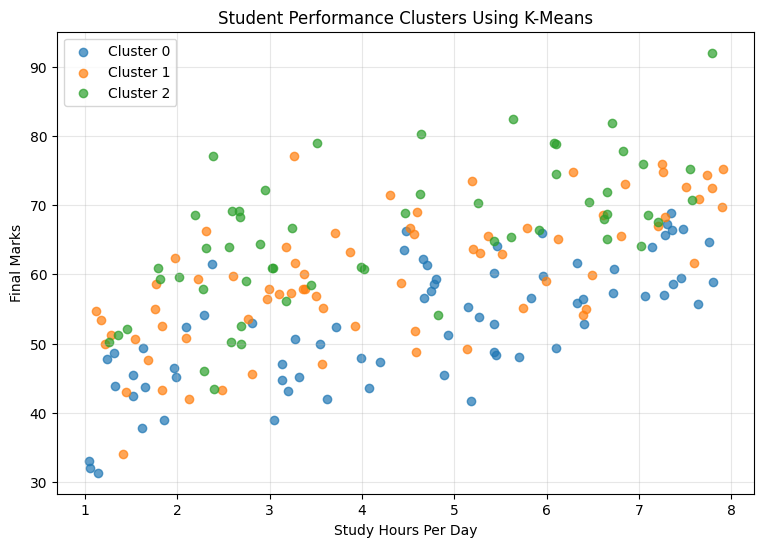

In [11]:

plt.figure(figsize=(9, 6))

for cluster_id in sorted(df["Cluster"].unique()):
    cluster_data = df[df["Cluster"] == cluster_id]

    plt.scatter(
        cluster_data["Study_Hours"],
        cluster_data["Final_Marks"],
        label=f"Cluster {cluster_id}",
        alpha=0.7
    )

plt.xlabel("Study Hours Per Day")
plt.ylabel("Final Marks")
plt.title("Student Performance Clusters Using K-Means")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


**Insight**: We compare the actual test marks with the marks predicted by Linear Regression.

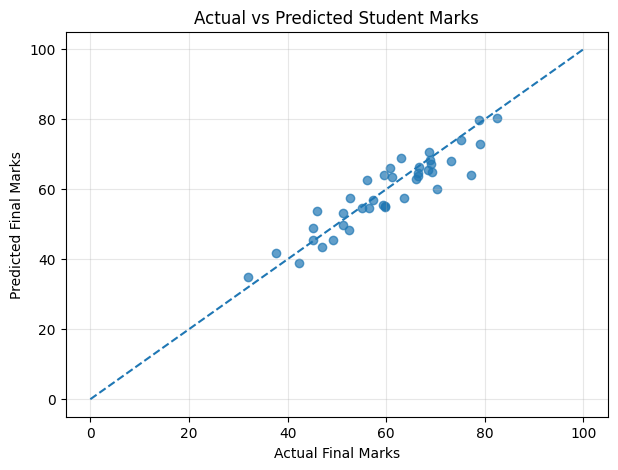

In [12]:

plt.figure(figsize=(7, 5))

plt.scatter(y_test, y_pred, alpha=0.7)

plt.plot(
    [0, 100], [0, 100],
    linestyle="--"
)

plt.xlabel("Actual Final Marks")
plt.ylabel("Predicted Final Marks")
plt.title("Actual vs Predicted Student Marks")
plt.grid(True, alpha=0.3)
plt.show()


**Insight**: We collect the key information from both machine learning approaches, including the number of students, algorithms, cluster counts, and model evaluation metrics.

In [13]:

print("=" * 45)
print("STUDENT PERFORMANCE ML PROJECT")
print("=" * 45)

print("\n1. Total Students:", len(df))
print("2. Supervised Algorithm: Linear Regression")
print("3. Unsupervised Algorithm: K-Means Clustering")
print("4. Number of Clusters:", df["Cluster"].nunique())
print("5. Mean Absolute Error:", round(mae, 2))
print("6. R2 Score:", round(r2, 3))

print("\nCluster-wise student counts:")
print(df["Cluster"].value_counts().sort_index())

print("\nProject completed successfully!")


STUDENT PERFORMANCE ML PROJECT

1. Total Students: 200
2. Supervised Algorithm: Linear Regression
3. Unsupervised Algorithm: K-Means Clustering
4. Number of Clusters: 3
5. Mean Absolute Error: 3.69
6. R2 Score: 0.849

Cluster-wise student counts:
Cluster
0    72
1    72
2    56
Name: count, dtype: int64

Project completed successfully!


**Insight**: Exporting the dataset and predictions to CSV files makes the project outputs easy to save, share, and analyze outside Google Colab.

In [14]:

df.to_csv("student_performance_results.csv", index=False)
results.to_csv("prediction_results.csv", index=False)

print("Files created successfully!")


Files created successfully!


In [15]:

from google.colab import files

files.download("student_performance_results.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

**Final project conclusion**

The project demonstrates how supervised and unsupervised learning can work together in a student performance analysis system. Linear Regression predicts numerical marks, while K-Means discovers groups of students with similar characteristics. Evaluation metrics and visualizations help us interpret the results.

**Future scope:** The system could be extended with real student datasets, a Streamlit dashboard, improved model comparisons, and personalized study recommendations.